In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import AllChem
import seaborn as sns
import scipy.stats  

## Data

In [2]:
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"

# Replace with your seed SMILES
seed_smiles = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"


In [3]:
df1 = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx") # GT
print(df1.shape)
df1.head(2)

(18806, 13)


,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP
0,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.0,NaN
1,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.3,NaN


In [6]:
df2 = pd.read_csv("/home/ec2-user/SageMaker/data/interim/molmim/unguided/molmim-2seeds_R1.csv", sep=";")
print(df2.shape)
df2.head(2) 

(80, 4)


,smiles,score,LogP,QED
0,CCn1cnc(NC(=O)C2CC(c3cccc(Br)c3)C2)n1,0.922266,3.1928,0.922266
1,CCn1cnc(NC(=O)C2CC(c3cccc(Br)c3)C2)n1,0.922266,3.1928,0.922266


In [7]:
df3_1 = pd.read_csv("/home/ec2-user/SageMaker/data/interim/molmim/guided/v2/BCS-CE65417_QSARAIH_b1.csv", sep=";")
df3_2 = pd.read_csv("/home/ec2-user/SageMaker/data/interim/molmim/guided/v2/BCS-CE65417_QSARAIH_b2.csv", sep=";")
df3_3 = pd.read_csv("/home/ec2-user/SageMaker/data/interim/molmim/guided/v2/BCS-CN20332_QSARAIH_b1.csv", sep=";")
df3_4 = pd.read_csv("/home/ec2-user/SageMaker/data/interim/molmim/guided/v2/BCS-CN20332_QSARAIH_b2.csv", sep=";")
df3 = pd.concat([df3_1, df3_2, df3_3, df3_4], ignore_index=True)
print(df3.shape)
df3.head(2)

(364, 4)


,valid_smiles,LogP,QED,AIH
0,CCn1cc(C(=O)NC2CC[C@@H](OC)C2)c2ccccc21,2.95850,0.938734,NaN
1,CCn1ccc(C(=O)NC2CN(C(=O)Oc3ccccc3)C2)c1C,2.42942,0.937910,NaN


In [37]:
df3 = pd.read_csv("../../data/interim/molmim/guided/v2/all_base_results_both_smiles.csv", sep=";")
print(df3.shape)
df3.head(2)

(75, 4)


,valid_smiles,LogP,QED,AIH
0,Cn1nccc1CNC(=O)[C@@]1(C)CC(c2ccccc2)=NO1,1.61960,0.932296,179.41
1,Cc1cccc(CNC(=O)[C@@]2(C)CC(c3ccccc3)=NO2)c1,3.19452,0.942751,178.30


## Add descriptors

In [38]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors


# Function to calculate LogP
def calculate_logp(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        return Descriptors.MolLogP(mol)
    else:
        return None

# Function to calculate Molecular Weight
def calculate_molecular_weight(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        return Descriptors.MolWt(mol)
    else:
        return None  # Return None if the SMILES is invalid

# Apply the function to the SMILES column and create a new LogP column
df1['LogP'] = df1['std_smiles'].apply(calculate_logp)
df2['LogP'] = df2['smiles'].apply(calculate_logp)
df3['LogP'] = df3['valid_smiles'].apply(calculate_logp)

# Apply the functions to the SMILES column and create new columns
df1['MW'] = df1['std_smiles'].apply(calculate_molecular_weight)
df2['MW'] = df2['smiles'].apply(calculate_molecular_weight)
df3['MW'] = df3['valid_smiles'].apply(calculate_molecular_weight)

In [39]:
from by_scorer_new import MoleculeScorer
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=True,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=False,
    similarity_weight=1.0,
    similarity_threshold=1.0,
)
#df1['AIH'] = scorer2.get_qsar_aih_predictions(df1['smiles'])
#df1['HSEC'] = scorer2.get_qsar_hsec_predictions(df1['smiles'])
#df2['AIH'] = scorer2.get_qsar_aih_predictions(df2['valid_smiles'])
#df2['HSEC'] = scorer2.get_qsar_hsec_predictions(df2['valid_smiles'])

In [40]:
# DF1 is already scored by Joerg - just rename
df1.rename(columns={"AI_H": "AIH"}, inplace=True)

In [41]:
df1.head(2)

,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AIH,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP,LogP,MW
11828,BCS-DK33075,['BCS-DK33075'],O=C(O)[C@@H]1C=C[C@H](NC(=O)[C@@]2(CF)CC(c3cc(...,470.0,320.0,333.0,345.0,285.0,350.0,0.86,1.98,2720.00,818.383675,1.9430,368.311
11324,BCS-DH31243,['BCS-DH31243'],COC(=O)[C@@H]1C=C[C@H](NC(=O)[C@@]2(C)CC(c3cc(...,468.0,316.0,298.0,280.0,286.0,303.0,2.58,2.60,22.41,808.913920,2.0818,364.348


In [12]:
results2 = scorer.score(df2['smiles'])
df2['AIH'] = results2.qsar_aih_scores
df2['HSEC'] = results2.qsar_hsec_scores
df2.head(2)

#~now scoring~#
#~Done scoring~#


,smiles,score,LogP,QED,AIH,HSEC
0,CCn1cnc(NC(=O)C2CC(c3cccc(Br)c3)C2)n1,0.922266,3.1928,0.922266,53.39,44.86
1,CCn1cnc(NC(=O)C2CC(c3cccc(Br)c3)C2)n1,0.922266,3.1928,0.922266,53.39,44.86


In [42]:
results3 = scorer.score(df3['valid_smiles'])
df3['AIH'] = results3.qsar_aih_scores
df3['HSEC'] = results3.qsar_hsec_scores
df3.head(2)

#~now scoring~#
#~Done scoring~#


,valid_smiles,LogP,QED,AIH,MW,HSEC
0,Cn1nccc1CNC(=O)[C@@]1(C)CC(c2ccccc2)=NO1,1.61960,0.932296,179.41,298.346,143.90
1,Cc1cccc(CNC(=O)[C@@]2(C)CC(c3ccccc3)=NO2)c1,3.19452,0.942751,178.30,308.381,136.45


## Sort for later Top@K analysis

In [43]:
df1.sort_values(by="AIH", ascending=False, inplace=True)
df2.sort_values(by="AIH", ascending=False, inplace=True)
df3.sort_values(by="AIH", ascending=False, inplace=True)

## Analysis 

In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def create_comparison_boxplots(df1, df2, columns=['LogP', 'MW', 'AIH', 'HSEC'], name1='Dataset 1', name2='Dataset 2'):
    # Set figure size and style
    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")
    
    # Create subplots - one for each column
    fig, axes = plt.subplots(2, 2, figsize=(8, 6))  # Adjusted size for better visibility
    axes = axes.flatten()
    
    # Define colors for each dataframe
    colors = ['#3498db', '#86ce28']
    
    # Create boxplots for each column
    for i, column in enumerate(columns):
        # Create a temporary dataframe for plotting
        temp_df = pd.DataFrame({
            name1: df1[column],
            name2: df2[column]
        })
        
        # Melt the dataframe for seaborn
        melted_df = pd.melt(temp_df, var_name='Dataset', value_name=column)
        
        # Create boxplot (using hue instead of palette to avoid FutureWarning)
        sns.boxplot(x='Dataset', y=column, hue='Dataset', data=melted_df, palette=colors, ax=axes[i])
        
        # Set title and style
        axes[i].set_title(f'{column}', fontweight='bold')
        axes[i].set_xlabel('')  # Remove x-axis label
        axes[i].grid(True, linestyle='--', alpha=0.7)
    
    # Add a legend outside the plots
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, [name1, name2], loc='upper right', title='Datasets', fontsize='medium')
    
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make space for the legend
    plt.show()


<Figure size 1000x600 with 0 Axes>

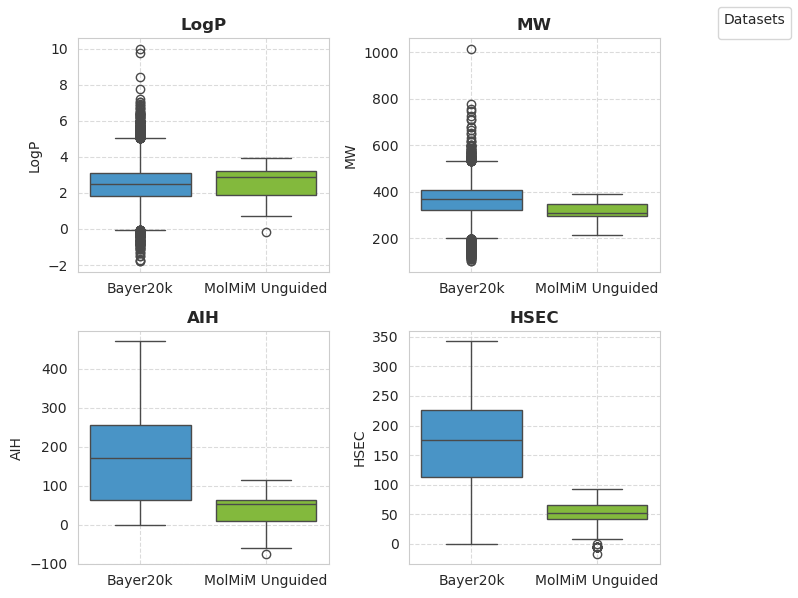

In [45]:

# Example usage
create_comparison_boxplots(df1, df2, name1="Bayer20k", name2="MolMiM Unguided")

<Figure size 1000x600 with 0 Axes>

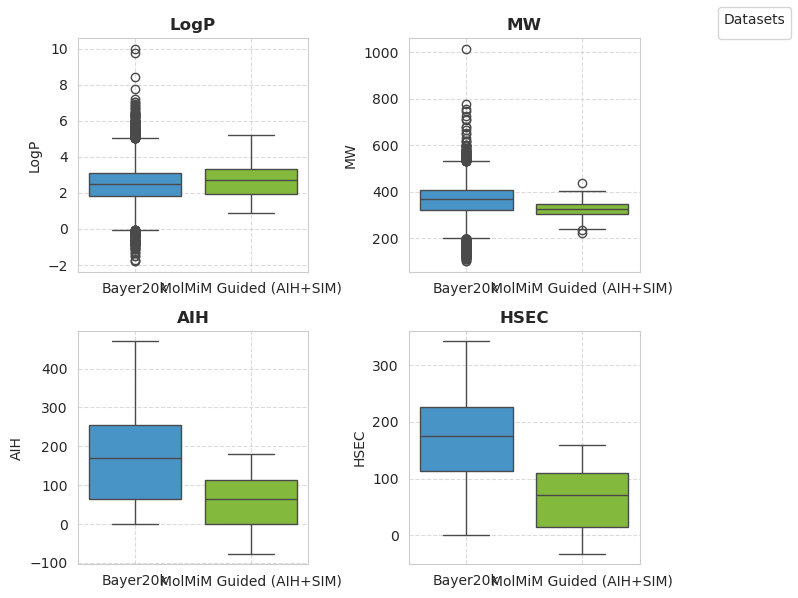

In [46]:
# Example usage
create_comparison_boxplots(df1, df3, name1="Bayer20k", name2="MolMiM Guided (AIH+SIM)")

### ANALYSE TopK (K=10)

<Figure size 1000x600 with 0 Axes>

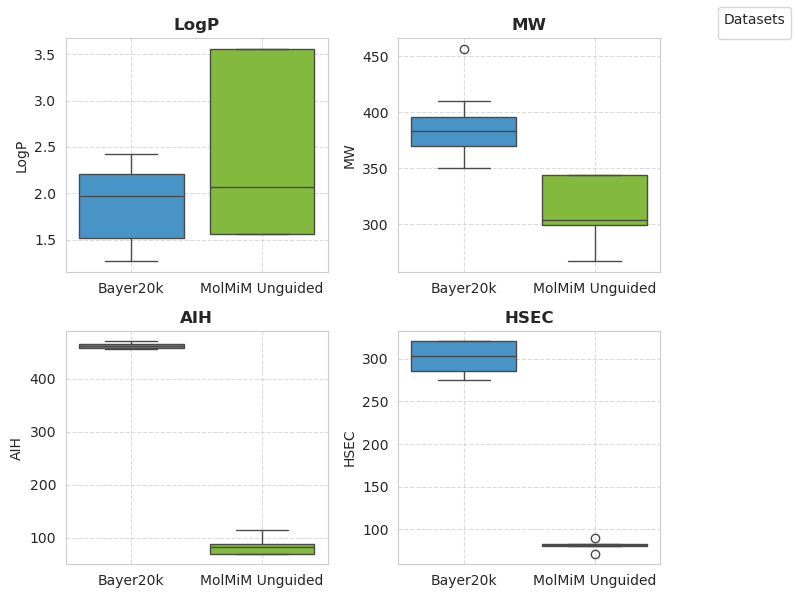

In [25]:
# Example usage
create_comparison_boxplots(df1[:10], df2[:10], name1="Bayer20k", name2="MolMiM Unguided")

<Figure size 1000x600 with 0 Axes>

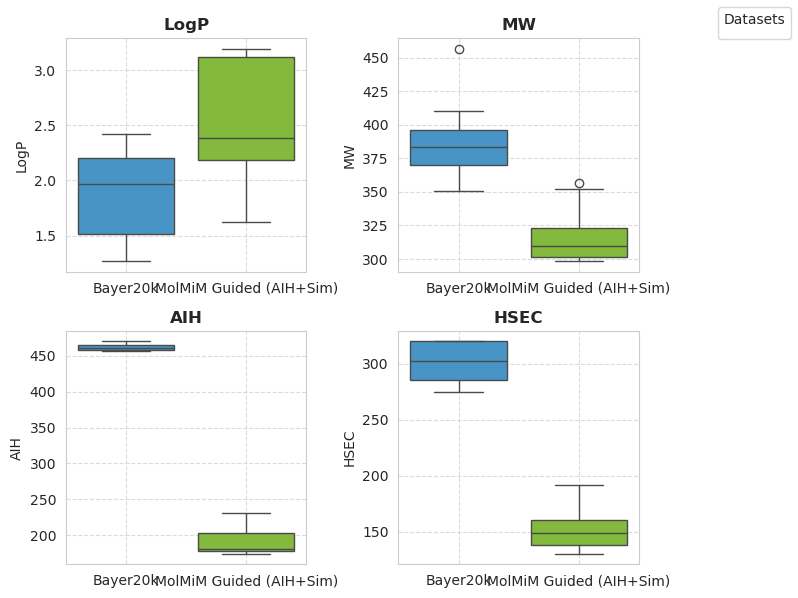

In [26]:
# Example usage
create_comparison_boxplots(df1[:10], df3[:10], name1="Bayer20k", name2="MolMiM Guided (AIH+Sim)")

# compare all three

In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def create_comparison_boxplots3(df1, df2, df3, columns=['LogP', 'MW', 'AIH', 'HSEC'], name1='Dataset 1', name2='Dataset 2', name3='Dataset 3'):
    # Set figure size and style
    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")
    
    # Create subplots - one for each column
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))  # Adjusted size for better visibility
    axes = axes.flatten()
    
    # Define colors for each dataframe
    colors = ['#3498db', '#86ce28', '#e74c3c']  # Added a color for the third dataframe
    
    # Create boxplots for each column
    for i, column in enumerate(columns):
        # Create a temporary dataframe for plotting
        temp_df = pd.DataFrame({
            name1: df1[column],
            name2: df2[column],
            name3: df3[column]
        })
        
        # Melt the dataframe for seaborn
        melted_df = pd.melt(temp_df, var_name='Dataset', value_name=column)
        
        # Create boxplot (using hue instead of palette to avoid FutureWarning)
        sns.boxplot(x='Dataset', y=column, hue='Dataset', data=melted_df, palette=colors, ax=axes[i])
        
        # Set title and style
        axes[i].set_title(f'{column}', fontweight='bold')
        axes[i].set_xlabel('')  # Remove x-axis label
        axes[i].grid(True, linestyle='--', alpha=0.7)
        # rotate
        #axes[i].tick_params(axis='x', rotation=45)
        new_labels = [name1.replace(' ', '\n'), name2.replace(' ', '\n'), name3.replace(' ', '\n')]
        axes[i].set_xticklabels(new_labels, rotation=0)
    
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make space for the legend
    plt.show()


/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)
/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)
/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)
/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)


<Figure size 1000x600 with 0 Axes>

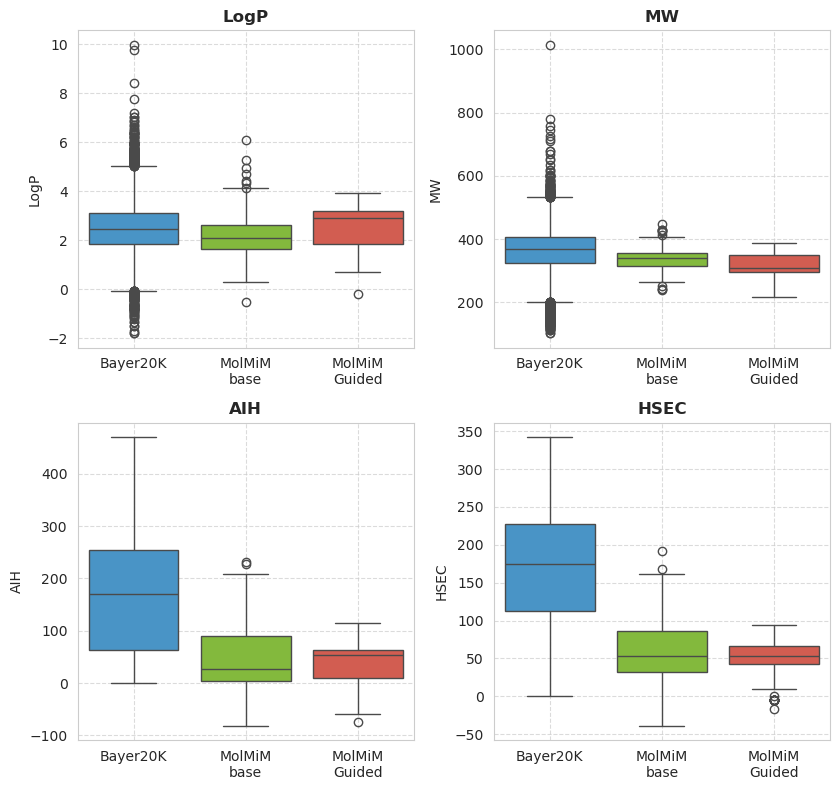

In [36]:
create_comparison_boxplots3(df1, df2, df3, name1="Bayer20K", name2="MolMiM base", name3="MolMiM Guided")

/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)
/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)
/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)
/tmp/ipykernel_16672/3462207750.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(new_labels, rotation=0)


<Figure size 1000x600 with 0 Axes>

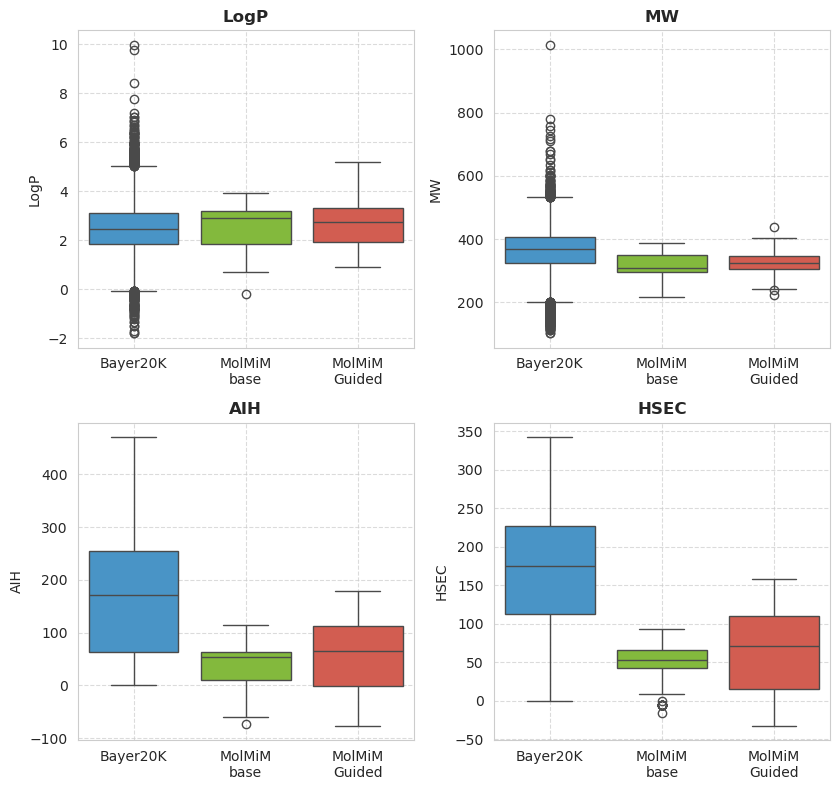

In [48]:
create_comparison_boxplots3(df1, df2, df3, name1="Bayer20K", name2="MolMiM base", name3="MolMiM Guided")